PLANETARY DEFENSE ANALYSIS - CLUSTERING

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [17]:
df = pd.read_csv('pha_dataset.csv')

C:\Users\Aishwarya\AppData\Local\Temp\ipykernel_31276\994728929.py:1: DtypeWarning: Columns (3: pdes, 4: name, 5: prefix) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('pha_dataset.csv')


In [3]:
df.shape

(958524, 45)

In [4]:
df.head()

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 958524 entries, 0 to 958523
Data columns (total 45 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              958524 non-null  str    
 1   spkid           958524 non-null  int64  
 2   full_name       958524 non-null  str    
 3   pdes            958524 non-null  object 
 4   name            22064 non-null   str    
 5   prefix          18 non-null      str    
 6   neo             958520 non-null  str    
 7   pha             938603 non-null  str    
 8   H               952261 non-null  float64
 9   diameter        136209 non-null  float64
 10  albedo          135103 non-null  float64
 11  diameter_sigma  136081 non-null  float64
 12  orbit_id        958524 non-null  str    
 13  epoch           958524 non-null  float64
 14  epoch_mjd       958524 non-null  int64  
 15  epoch_cal       958524 non-null  float64
 16  equinox         958524 non-null  str    
 17  e               95852

In [18]:
#Dropping unnecessary columns
df =df.drop(columns=['id','spkid','pdes', 'full_name','name','prefix','equinox','orbit_id']) # Identifiers
df = df.drop(columns=['sigma_e','sigma_a','sigma_q','sigma_i','sigma_om','sigma_w','sigma_ma','sigma_ad','sigma_n','sigma_tp','sigma_per']) # sigma columns

In [19]:
df.columns

Index(['neo', 'pha', 'H', 'diameter', 'albedo', 'diameter_sigma', 'epoch',
       'epoch_mjd', 'epoch_cal', 'e', 'a', 'q', 'i', 'om', 'w', 'ma', 'ad',
       'n', 'tp', 'tp_cal', 'per', 'per_y', 'moid', 'moid_ld', 'class', 'rms'],
      dtype='str')

In [20]:
df.drop(columns=['neo', 'pha', 'diameter_sigma', 'epoch',
       'epoch_mjd', 'epoch_cal','class',], inplace=True)

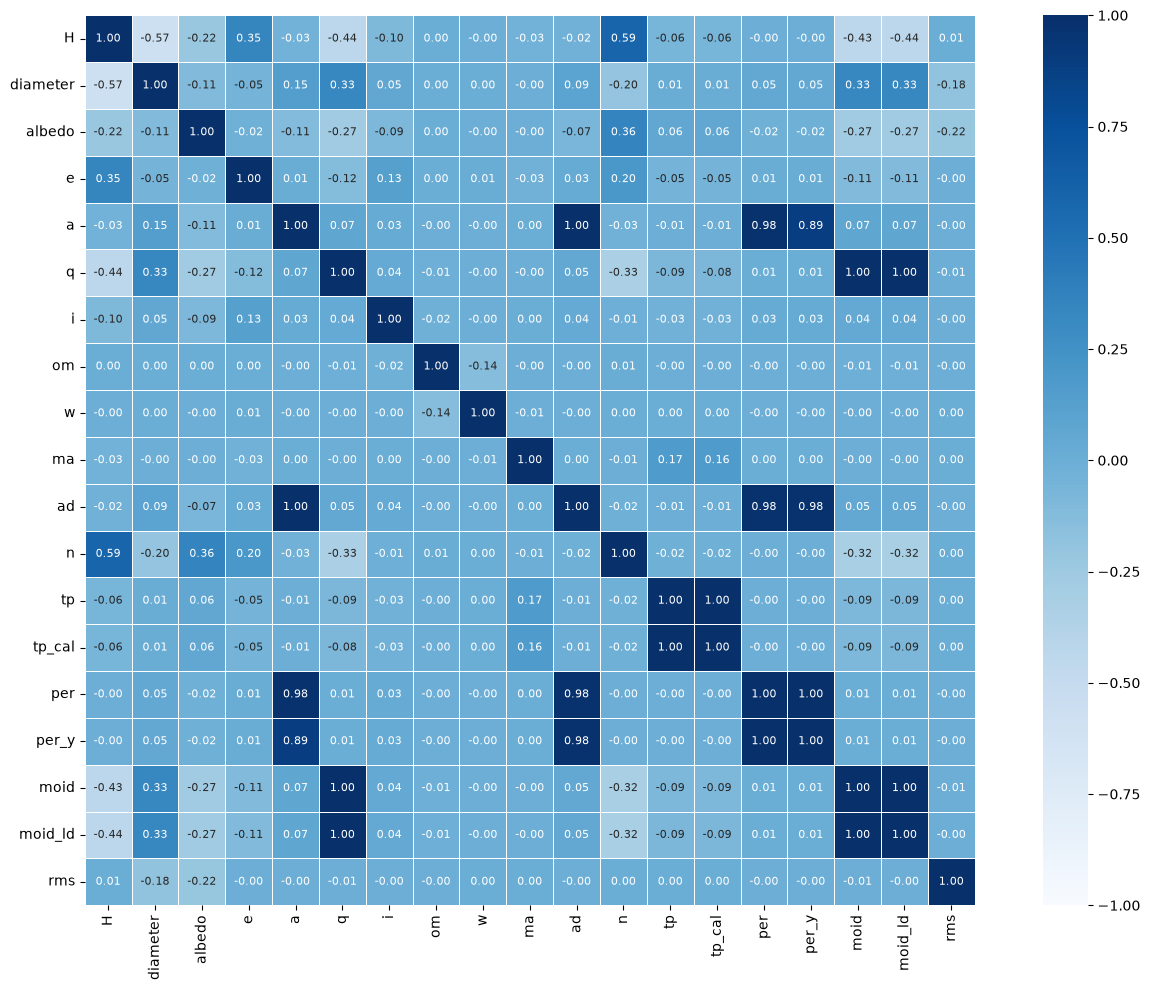

In [21]:
corr = df.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, cmap="Blues", vmin=-1, vmax=1,fmt=".2f", linewidths=0.5, annot_kws={"size": 8},
    square=True)
plt.tight_layout()
plt.show()

In [22]:
df.drop(columns=['ad','moid', 'moid_ld','per', 'per_y', 'tp'], inplace=True)

In [23]:
df.columns.tolist()

['H',
 'diameter',
 'albedo',
 'e',
 'a',
 'q',
 'i',
 'om',
 'w',
 'ma',
 'n',
 'tp_cal',
 'rms']

In [24]:
df.isnull().sum()

H             6263
diameter    822315
albedo      823421
e                0
a                0
q                0
i                0
om               0
w                0
ma               1
n                0
tp_cal           0
rms              2
dtype: int64

In [25]:
df.drop(columns=['diameter', 'albedo'], inplace=True)

In [26]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')
cols = ['H','ma','rms']
df[cols] = imputer.fit_transform(df[cols])

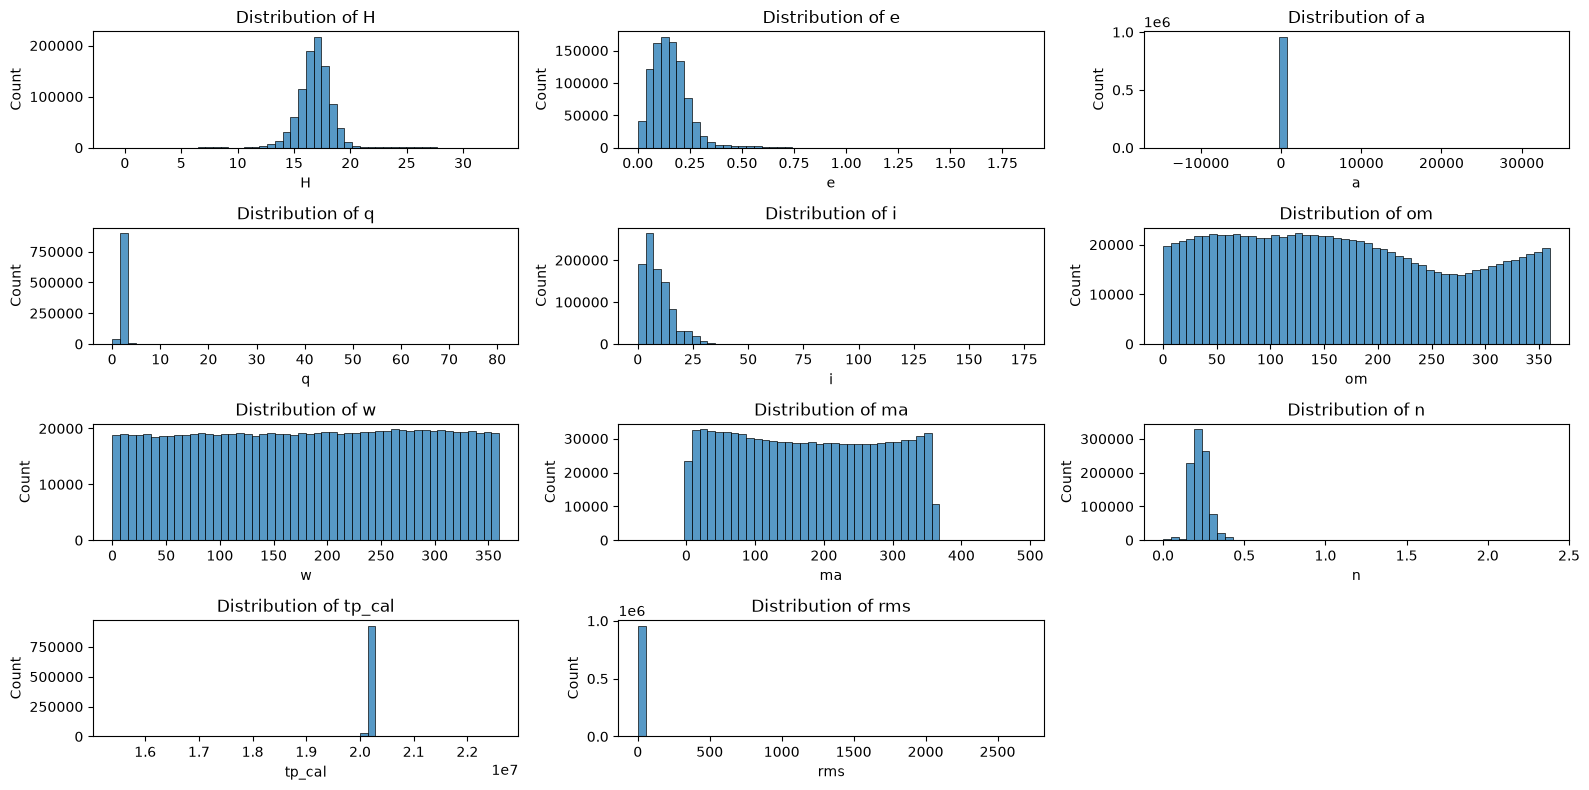

In [27]:
fig, axes = plt.subplots(4,3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(df.columns):
    sns.histplot(df[col], bins=50, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

In [28]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
print(X_scaled.shape)

(958524, 11)


Model

In [32]:
import os
import json
import warnings
import mlflow
import mlflow.sklearn
import shap

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

c:\Users\Aishwarya\OneDrive\Documents\DATA SCIENCE\Projects\Project_3_Planetary_Defense\pha_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [33]:
from sklearn.cluster import KMeans  
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from mlflow.models import infer_signature

In [34]:
k_values = range(2, 11)

inertia_values = []
silhouette_values = []
k_results = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia = float(kmeans.inertia_)

    sample_size = min(2000, len(X_scaled))

    silhouette = float(
        silhouette_score(
            X_scaled,
            labels,
            sample_size=sample_size if sample_size < len(X_scaled) else None,
            random_state=42
        )
    )

    inertia_values.append(inertia)
    silhouette_values.append(silhouette)

    k_results.append({
        "k": k,
        "inertia": inertia,
        "silhouette_score": silhouette
    })

k_results_df = pd.DataFrame(k_results)

display(k_results_df)

,k,inertia,silhouette_score
0,2,9.516357e+06,0.877159
1,3,8.762716e+06,0.122188
2,4,7.789609e+06,0.132438
3,5,6.990823e+06,0.143790
4,6,6.522001e+06,0.132419
5,7,5.839417e+06,0.129864
6,8,5.445826e+06,0.136787
7,9,5.082455e+06,0.137122
8,10,4.820438e+06,0.133275


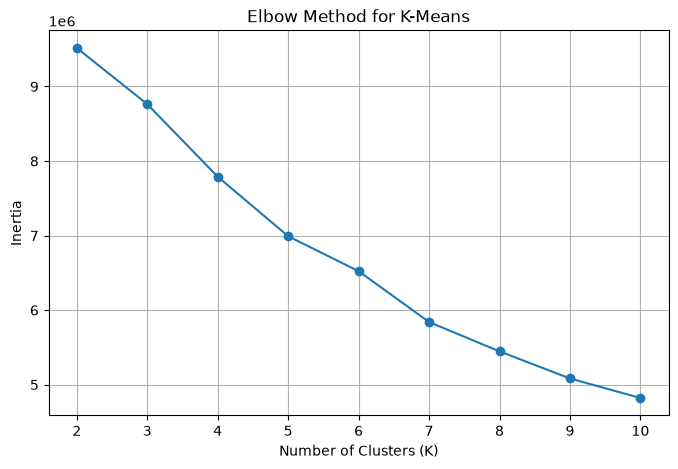

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

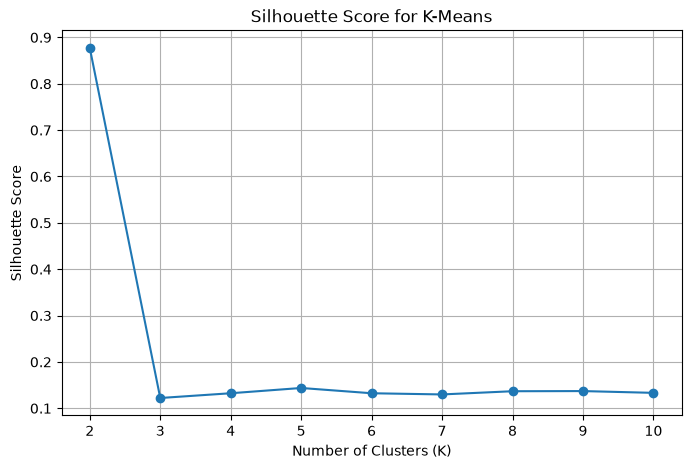

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [37]:
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("Asteroid_Clustering")

<Experiment: artifact_location='mlflow-artifacts:/3', creation_time=1792662371958, effective_trace_archival_retention=None, experiment_id='3', last_update_time=1792662371958, lifecycle_stage='active', name='Asteroid_Clustering', tags={}, trace_location=None, workspace='default'>

In [38]:
for row in k_results:

    with mlflow.start_run(
        run_name=f"KMeans_Selection_K{row['k']}"
    ):

        mlflow.log_params({
            "algorithm": "KMeans",
            "n_clusters": row["k"],
            "n_init": 10,
            "random_state": 42
        })

        mlflow.log_metrics({
            "inertia": row["inertia"],
            "silhouette_score": row["silhouette_score"]
        })

        print(f"Logged K-Means candidate: K={row['k']}")

Logged K-Means candidate: K=2
🏃 View run KMeans_Selection_K2 at: http://localhost:5000/#/experiments/3/runs/bffd759c6eaf479bace6971e3a176168
🧪 View experiment at: http://localhost:5000/#/experiments/3
Logged K-Means candidate: K=3
🏃 View run KMeans_Selection_K3 at: http://localhost:5000/#/experiments/3/runs/70709afdbda1482d9848d9a5162db87a
🧪 View experiment at: http://localhost:5000/#/experiments/3
Logged K-Means candidate: K=4
🏃 View run KMeans_Selection_K4 at: http://localhost:5000/#/experiments/3/runs/0e9fe65fd0a64e9fa35f7bb83bf16833
🧪 View experiment at: http://localhost:5000/#/experiments/3
Logged K-Means candidate: K=5
🏃 View run KMeans_Selection_K5 at: http://localhost:5000/#/experiments/3/runs/c8b7166d9acb4b03ab0d73a158e296a5
🧪 View experiment at: http://localhost:5000/#/experiments/3
Logged K-Means candidate: K=6
🏃 View run KMeans_Selection_K6 at: http://localhost:5000/#/experiments/3/runs/9927ebb06f454f03be767767dd16e3c9
🧪 View experiment at: http://localhost:5000/#/experimen

In [46]:
best_k = 5
final_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=best_k,
        n_init=10,
        random_state=42
    ))
])

with mlflow.start_run(run_name="KMeans_Final_Model") as final_run:

    final_labels = final_pipeline.fit_predict(df)

    X_final_scaled = final_pipeline[:-1].transform(df)

    final_inertia = float(
        final_pipeline.named_steps["kmeans"].inertia_
    )

    final_silhouette = float(
        silhouette_score(
            X_final_scaled,
            final_labels,
            sample_size=(
                min(2000, len(X_final_scaled))
                if len(X_final_scaled) > 2000
                else None
            ),
            random_state=42
        )
    )

    final_davies_bouldin = float(
        davies_bouldin_score(
            X_final_scaled,
            final_labels
        )
    )

    final_calinski_harabasz = float(
        calinski_harabasz_score(
            X_final_scaled,
            final_labels
        )
    )

    mlflow.log_params({
        "algorithm": "KMeans",
        "n_clusters": best_k,
        "n_init": 10,
        "random_state": 42
    })

    mlflow.log_metrics({
        "inertia": final_inertia,
        "silhouette_score": final_silhouette,
        "davies_bouldin_score": final_davies_bouldin,
        "calinski_harabasz_score": final_calinski_harabasz
    })

    print("Final model trained successfully.")
    print("Number of clusters:", best_k)
    print("Inertia:", final_inertia)
    print("Silhouette Score:", final_silhouette)
    print("Davies-Bouldin Score:", final_davies_bouldin)
    print("Calinski-Harabasz Score:", final_calinski_harabasz)

    signature = infer_signature(
    df.head(min(5, len(df))),
        final_labels[:min(5, len(df))]
    )

    mlflow.sklearn.log_model(
        sk_model=final_pipeline,
        name="model",
        signature=signature,
        input_example=df.head(min(5, len(df))),
        skops_trusted_types=["numpy.dtype"]
    )

    print("Final K-Means model logged successfully.")

Final model trained successfully.
Number of clusters: 5
Inertia: 6990822.9839561675
Silhouette Score: 0.14379049090545223
Davies-Bouldin Score: 1.3458010367192244
Calinski-Harabasz Score: 121786.86848927701


Final K-Means model logged successfully.
🏃 View run KMeans_Final_Model at: http://localhost:5000/#/experiments/3/runs/78837224bec940109fdf93275547c9f9
🧪 View experiment at: http://localhost:5000/#/experiments/3


In [47]:
model_uri = f"runs:/{final_run.info.run_id}/model"

registered_model = mlflow.register_model(
    model_uri=model_uri,
    name="Asteroid_KMeans_Model"
)

print("Registered model: Asteroid_KMeans_Model")
print("Model version:", registered_model.version)

Registered model 'Asteroid_KMeans_Model' already exists. Creating a new version of this model...
2026/10/22 16:31:00 WARNING mlflow.tracking._model_registry.fluent: Run with id 78837224bec940109fdf93275547c9f9 has no artifacts at artifact path 'model', registering model based on models:/m-789543c2d54d4dce9572648cdd4647c9 instead
2026/10/22 16:31:01 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Asteroid_KMeans_Model, version 1


Registered model: Asteroid_KMeans_Model
Model version: 1


Created version '1' of model 'Asteroid_KMeans_Model'.


In [48]:
clustered_df = df.copy()

clustered_df["cluster"] = final_labels

os.makedirs("artifacts", exist_ok=True)

clustered_df.to_csv(
    "artifacts/clustered_asteroids.csv",
    index=False
)

print("Clustered dataset saved successfully.")

display(clustered_df.head())

Clustered dataset saved successfully.


,H,e,a,q,i,om,w,ma,n,tp_cal,rms,cluster
0,3.40,0.076009,2.769165,2.558684,10.594067,80.305531,73.597695,77.372098,0.213885,2.018043e+07,0.43301,3
1,4.20,0.229972,2.773841,2.135935,34.832932,173.024741,310.202392,144.975675,0.213345,2.018072e+07,0.35936,3
2,5.33,0.256936,2.668285,1.982706,12.991043,169.851482,248.066193,125.435355,0.226129,2.018112e+07,0.33848,3
3,3.00,0.088721,2.361418,2.151909,7.141771,103.810804,150.728541,95.861938,0.271609,2.018051e+07,0.39980,3
4,6.90,0.190913,2.574037,2.082619,5.367427,141.571026,358.648418,17.846343,0.238661,2.020032e+07,0.52191,3


cluster
0     24088
1    452577
2         1
3    478454
4      3404
Name: count, dtype: int64


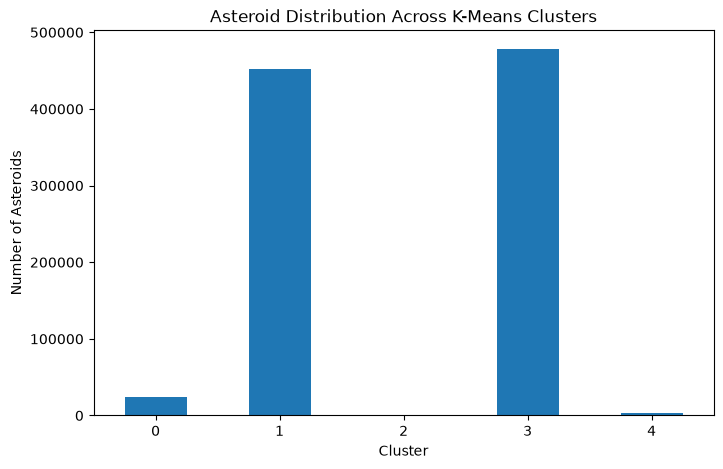

In [49]:
cluster_counts = clustered_df["cluster"].value_counts().sort_index()

print(cluster_counts)

cluster_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Cluster")
plt.ylabel("Number of Asteroids")
plt.title("Asteroid Distribution Across K-Means Clusters")
plt.xticks(rotation=0)
plt.show()